# 05: Customer segments and campaign recommendations
**Goal:** turn the scores from notebook 04 into groups of customers, and say what the business should do with each group.

Notebook 04 told us who is worth the most (predicted LTV) and who is probably leaving (churn risk). Here we combine the two into five segments, size each one, and attach a recommended campaign.

Make sure to run notebook 04 first, as tt creates the file this notebook reads.

## Step 1: Load the customer scores
One row per customer, saved by notebook 04. Recall that `churn_risk` is only relevant for repeat buyers. One-time buyers always show 0, so we treat them as their own group.

In [14]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent
scores = pd.read_csv(PROJECT_ROOT / "data" / "exports" / "customer_scores.csv")
repeat_buyers = scores[scores["repeat_buyer"]]
one_time_buyers = scores[~scores["repeat_buyer"]]

print(f"{len(scores):,} total customers")
print(f"{len(repeat_buyers):,} repeat buyers ({len(repeat_buyers)/len(scores):.0%})")
print(f"{len(one_time_buyers):,} one-time buyers ({len(one_time_buyers)/len(scores):.0%})")
scores.head().style.format({
    "frequency": "{:.0f}",
    "recency": "{:.0f}",
    "T": "{:.0f}",
    "monetary_value": "${:,.0f}",
    "p_alive": "{:.1%}",
    "pred_purchases_12m": "{:.2f}",
    "pred_order_value": "${:,.0f}",
    "ltv_12m": "${:,.0f}",
    "churn_risk": "{:.1%}",
})

5,878 total customers
4,189 repeat buyers (71%)
1,689 one-time buyers (29%)


,Customer_ID,repeat_buyer,frequency,recency,T,monetary_value,p_alive,pred_purchases_12m,pred_order_value,ltv_12m,ltv_decile,churn_risk
0,12346,True,7,400,725,$997,62.6%,2.19,$999,"$2,186",9,37.4%
1,12347,True,7,402,404,$717,99.0%,5.79,$720,"$4,166",10,1.0%
2,12348,True,4,363,438,$449,96.4%,3.20,$453,"$1,451",8,3.6%
3,12349,True,3,571,589,$997,97.5%,1.96,"$1,003","$1,970",9,2.5%
4,12350,False,0,0,310,$0,100.0%,0.63,$362,$227,3,0.0%


## Step 2: Choose the cut-offs
We split repeat buyers on two questions:
- **Is the customer high value?** Predicted 12-month LTV at or above the repeat-buyer median.
- **Is the customer at risk?** Churn risk at or above **0.25**. We use 0.25, not 0.5, because most repeat buyers have a very low churn risk (the middle customer is about 0.04). A 0.5 cut-off would flag only about 7% of them and miss people who are slipping away.

Note that both cut-offs arbitrary; we can change them below and the following cells will update if we rerun them.

In [5]:
RISK_CUTOFF = 0.25

repeat = scores[scores["repeat_buyer"]]
VALUE_CUTOFF = repeat["ltv_12m"].median()

print(f"High value = predicted LTV of ${VALUE_CUTOFF:,.0f} or more")
print(f"At risk    = churn risk of {RISK_CUTOFF} or more "
      f"({(repeat['churn_risk'] >= RISK_CUTOFF).mean():.0%} of repeat buyers)")

High value = predicted LTV of $797 or more
At risk    = churn risk of 0.25 or more (17% of repeat buyers)


## Step 3: Assign each customer to a segment
Five segments:

| Segment | Who they are |
|---|---|
| **Champions** | High value, low risk |
| **At-risk high value** | High value, high risk. Few customers, but each one is worth a personal effort. |
| **Loyal low-value** | Low value, low risk |
| **Fading low-value** | Low value, high risk |
| **One-time buyers** | Bought once. The model can't judge them yet. |

In [8]:
def assign_segment(row):
    if not row["repeat_buyer"]:
        return "One-time buyers"
    high_value = row["ltv_12m"] >= VALUE_CUTOFF
    at_risk = row["churn_risk"] >= RISK_CUTOFF
    if high_value and not at_risk:
        return "Champions"
    if high_value and at_risk:
        return "At-risk high value"
    if not high_value and not at_risk:
        return "Loyal low-value"
    return "Fading low-value"

scores["segment"] = scores.apply(assign_segment, axis=1)
scores["segment"].value_counts()

segment
Champions             2063
One-time buyers       1689
Loyal low-value       1431
Fading low-value       663
At-risk high value      32
Name: count, dtype: int64

## Step 4: Size each segment
For every segment: how many customers, their average predicted LTV, and what share of all predicted 12-month revenue they hold. This shows where the money is.

In [10]:
order = ["Champions", "At-risk high value", "Loyal low-value", "Fading low-value", "One-time buyers"]

summary = scores.groupby("segment").agg(
    customers=("Customer_ID", "count"),
    avg_ltv=("ltv_12m", "mean"),
    total_ltv=("ltv_12m", "sum"),
).reindex(order)
summary["share_of_customers"] = summary["customers"] / summary["customers"].sum()
summary["share_of_revenue"] = summary["total_ltv"] / summary["total_ltv"].sum()

summary.style.format({
    "customers": "{:,}",
    "avg_ltv": "${:,.0f}",
    "total_ltv": "${:,.0f}",
    "share_of_customers": "{:.1%}",
    "share_of_revenue": "{:.1%}",
})

,customers,avg_ltv,total_ltv,share_of_customers,share_of_revenue
segment,,,,,
Champions,"2,063","$3,038","$6,268,117",35.1%,82.2%
At-risk high value,32,"$1,802","$57,652",0.5%,0.8%
Loyal low-value,"1,431",$416,"$595,957",24.3%,7.8%
Fading low-value,663,$216,"$143,170",11.3%,1.9%
One-time buyers,"1,689",$329,"$556,270",28.7%,7.3%


## Step 5: Visualize the data
Two bars per segment: the share of customers vs the share of predicted revenue. We can see that most of our revenue comes from a small number of customers, relative to the revenue.

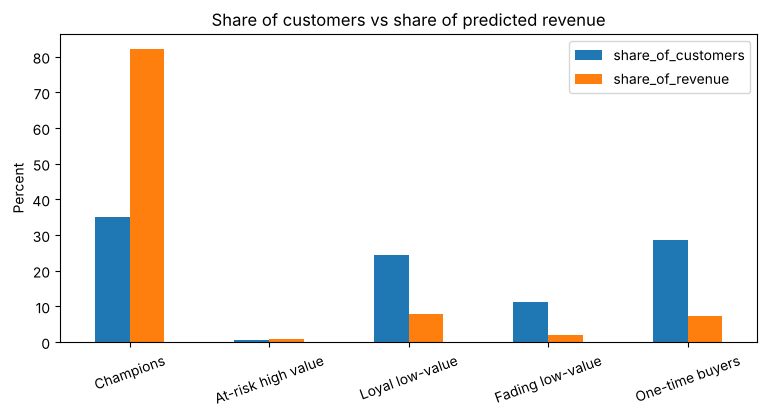

In [5]:
shares = summary[["share_of_customers", "share_of_revenue"]] * 100
shares.plot(kind="bar", figsize=(9, 4), title="Share of customers vs share of predicted revenue")
plt.ylabel("Percent")
plt.xlabel("")
plt.xticks(rotation=20)
plt.show()

## Step 6: Estimate what each campaign could be worth
Now the business question: if we run a campaign on each segment, how much revenue could it add?

**These rates are assumptions, not results.** They are placeholders based on common marketing assumptions, and the real numbers should come from an A/B test (send the campaign to half the segment and compare).

Extra revenue estimate= segment predicted revenue x assumed lift

In [11]:
#ASSUMED lifts (we can edit these as needed). Share of the segment's predicted revenue the campaign adds.
lift = {
    "Champions": 0.05,            # loyalty perks keep them buying a little more
    "At-risk high value": 0.20,   # personal win-back offer
    "Loyal low-value": 0.10,      # cross-sell and bundles to raise order size
    "Fading low-value": 0.05,     # automated email, not much lift expected
    "One-time buyers": 0.15,      # second-purchase offer
}

summary["assumed_lift"] = pd.Series(lift)
summary["extra_revenue"] = summary["total_ltv"] * summary["assumed_lift"]

print(f"Total extra 12-month revenue if every assumption holds: ${summary['extra_revenue'].sum():,.0f}")
summary[["customers", "total_ltv", "assumed_lift", "extra_revenue"]].style.format({
    "customers": "{:,}",
    "total_ltv": "${:,.0f}",
    "assumed_lift": "{:.0%}",
    "extra_revenue": "${:,.0f}",
})

Total extra 12-month revenue if every assumption holds: $475,131


,customers,total_ltv,assumed_lift,extra_revenue
segment,,,,
Champions,"2,063","$6,268,117",5%,"$313,406"
At-risk high value,32,"$57,652",20%,"$11,530"
Loyal low-value,"1,431","$595,957",10%,"$59,596"
Fading low-value,663,"$143,170",5%,"$7,159"
One-time buyers,"1,689","$556,270",15%,"$83,440"


## Step 7: Recommendations
One action per segment, with the size of the prize from Step 6 and a note on how heavily to spend. The rule of thumb: spend the most where the customers are worth the most, and keep the cheap, automated tactics for low-value groups.

In [13]:
actions = pd.DataFrame({
    "segment": order,
    "recommended_campaign": [
        "Loyalty perks and early access to new products. Do not discount as they already buy.",
        "Personal win-back: a targeted offer plus a call or account-manager check-in. Small group, so feasible to reach out individually.",
        "Cross-sell and bundles to raise order size. Standard email send.",
        "Automated reactivation email only. Do not spend on discounts here.",
        "Second-purchase offer within weeks of the first order, while their order is still fresh on their mind.",
    ],
    "spend_level": ["Medium", "High", "Low", "Very low", "Medium"],
})
recs = actions.merge(
    summary[["customers", "extra_revenue"]].round(0).reset_index(), on="segment")
recs = recs.sort_values("extra_revenue", ascending=False)
(recs.style
    .format({"customers": "{:,}", "extra_revenue": "${:,.0f}"})
    .hide(axis="index")
    .set_properties(subset=["recommended_campaign"],
                    **{"white-space": "normal", "text-align": "left", "min-width": "350px"})
    .set_properties(subset=["segment"], **{"font-weight": "bold", "text-align": "left"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
)

segment,recommended_campaign,spend_level,customers,extra_revenue
Champions,Loyalty perks and early access to new products. Do not discount as they already buy.,Medium,"2,063","$313,406"
One-time buyers,"Second-purchase offer within weeks of the first order, while their order is still fresh on their mind.",Medium,"1,689","$83,440"
Loyal low-value,Cross-sell and bundles to raise order size. Standard email send.,Low,"1,431","$59,596"
At-risk high value,"Personal win-back: a targeted offer plus a call or account-manager check-in. Small group, so feasible to reach out individually.",High,32,"$11,530"
Fading low-value,Automated reactivation email only. Do not spend on discounts here.,Very low,663,"$7,159"


## Step 8: Save the results
We save the customer list with its segment (so a campaign team could use it) and the recommendations table.

In [8]:
EXPORT_DIR = PROJECT_ROOT / "data" / "exports"
scores.to_csv(EXPORT_DIR / "customer_segments.csv", index=False)
recs.to_csv(EXPORT_DIR / "segment_recommendations.csv", index=False)
print("Saved customer_segments.csv and segment_recommendations.csv to data/exports/")

Saved customer_segments.csv and segment_recommendations.csv to data/exports/


## What we found, and what to be careful about

- Which segment holds the most predicted revenue, and how small is it as a share of customers?
- How many customers are in **At-risk high value**? It is small because the model lowers a customer's LTV when it thinks they are leaving, so few customers are both high value and high risk. That makes them easy to contact one by one.
- What share of customers are one-time buyers? (Notebook 04 showed most of them never return, so a second-purchase campaign is the biggest retention lever.)

**Limits:**
- The lift rates in Step 6 are assumptions. A real result needs A/B tests.
- LTV is capped for the biggest wholesale buyers (notebook 04), so Champions are understated.
- The risk and value cut-offs are arbitary. 
- Segments come from a forecast, not certainty; some customers will land in the wrong group.